In [2]:
import pandas as a


In [1]:
import numpy as yahoo

##Default Argument

In [3]:
df = a.DataFrame({'date':['3/10/2000','2/3/2000','12/6/2100'],'value':[2,3,4]})

In [4]:
df

,date,value
0,3/10/2000,2
1,2/3/2000,3
2,12/6/2100,4


In [8]:
df['date'] = a.to_datetime(df['date'])
df.info()



<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    3 non-null      datetime64[us]
 1   value   3 non-null      int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 180.0 bytes


In [9]:
df

,date,value
0,2000-03-10,2
1,2000-02-03,3
2,2100-12-06,4


##Day First Format##

In [8]:
df = a.DataFrame({'date':['3/10/2000','2/3/2000','12/6/2100'],'value':[2,3,4]})

# Assuming you imported pandas as a
df['date'] = a.to_datetime(df['date'], dayfirst=True)
df

,date,value
0,2000-10-03,2
1,2000-03-02,3
2,2100-06-12,4


In [10]:
df =a.DataFrame({'date':['2018-6-10 20:30:0',
                         '2019-3-9 19:30:0',
                         '2017-5-5 21:30:0'],'value':[2,3,4]})

df['date']=a.to_datetime(df['date'],format ="%Y-%d-%m %H:%M:%S")

In [10]:
df

,date,value
0,2018-10-06 20:30:00,2
1,2019-09-03 19:30:00,3
2,2017-05-05 21:30:00,4


***Handle Parsing Error***

In [11]:
df = a.DataFrame({'date':['3/10/2000','a/3/2000','12/6/2100'],'value':[2,3,4]})
df

,date,value
0,3/10/2000,2
1,a/3/2000,3
2,12/6/2100,4


In [12]:
import pandas as pd


df['date'] = pd.to_datetime(df['date'], errors='coerce')
df

,date,value
0,2018-10-06 20:30:00,2
1,2019-09-03 19:30:00,3
2,2017-05-05 21:30:00,4


In [13]:
df['date']=a.to_datetime(df['date'],errors ='coerce')
df

,date,value
0,2000-03-10,2
1,NaT,3
2,2100-12-06,4


***2. Assemble a datetime from multiple Columns***

In [18]:
df= a.DataFrame({'year':[2015,2016],
                 'month':[2,3],
                 'day':[4,5]})

df

,year,month,day
0,2015,2,4
1,2016,3,5


In [14]:
import pandas as a

In [19]:
df['date'] = a.to_datetime(df)
df

,year,month,day,date
0,2015,2,4,2015-02-04
1,2016,3,5,2016-03-05


###GET YEAR MONTH AND DAY###

In [20]:
df = a.DataFrame({'name':['Tom','Andy','Lucas'],
                  'DOB':['08-05-1997','02-03-2005','03-05-2009']})

df

,name,DOB
0,Tom,08-05-1997
1,Andy,02-03-2005
2,Lucas,03-05-2009


In [21]:
# 1. Convert the DOB column to datetime
df['DOB'] = a.to_datetime(df['DOB'], errors='coerce')

# 2. Extract year, month, and day
df['year'] = df['DOB'].dt.year
df['month'] = df['DOB'].dt.month
df['day'] = df['DOB'].dt.day

df

,name,DOB,year,month,day
0,Tom,1997-08-05,1997,8,5
1,Andy,2005-02-03,2005,2,3
2,Lucas,2009-03-05,2009,3,5


***Get the weak of the yaer and leap year ***

In [24]:
df['day_of_week'] = df['DOB'].dt.dayofweek
df['is_leap_year'] =df['DOB'].dt.is_leap_year
df

,name,DOB,year,month,day,day_of_week,is_leap_year
0,Tom,1997-08-05,1997,8,5,1,False
1,Andy,2005-02-03,2005,2,3,3,False
2,Lucas,2009-03-05,2009,3,5,3,False


In [25]:
df['DOB'].dt.weekday

0    1
1    3
2    3
Name: DOB, dtype: int32

In [26]:
dw_mapping ={
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
    
}

df['day_of_week_name'] =df['DOB'].dt.weekday.map(dw_mapping)
df

,name,DOB,year,month,day,day_of_week,is_leap_year,day_of_week_name
0,Tom,1997-08-05,1997,8,5,1,False,Tuesday
1,Andy,2005-02-03,2005,2,3,3,False,Thursday
2,Lucas,2009-03-05,2009,3,5,3,False,Thursday


In [27]:
df['age'] = (a.Timestamp.now() - df['DOB']).dt.days // 365
df

,name,DOB,year,month,day,day_of_week,is_leap_year,day_of_week_name,age
0,Tom,1997-08-05,1997,8,5,1,False,Tuesday,29
1,Andy,2005-02-03,2005,2,3,3,False,Thursday,21
2,Lucas,2009-03-05,2009,3,5,3,False,Thursday,17


In [28]:
a.to_datetime('today').year -df['DOB'].dt.year

0    29
1    21
2    17
Name: DOB, dtype: int32

In [29]:
today =a.to_datetime('today')
df['age']=today.year-df['DOB'].dt.year
df

,name,DOB,year,month,day,day_of_week,is_leap_year,day_of_week_name,age
0,Tom,1997-08-05,1997,8,5,1,False,Tuesday,29
1,Andy,2005-02-03,2005,2,3,3,False,Thursday,21
2,Lucas,2009-03-05,2009,3,5,3,False,Thursday,17


In [30]:
# Year difference
today =a.to_datetime('today')

diff_y=today.year -df['DOB'].dt.year

# Haven't had birthday

b_md = df['DOB'].apply(lambda x:(x.month,x.day))
no_birthday =b_md>(today.month,today.day)
df['age']=diff_y - no_birthday
df

,name,DOB,year,month,day,day_of_week,is_leap_year,day_of_week_name,age
0,Tom,1997-08-05,1997,8,5,1,False,Tuesday,29
1,Andy,2005-02-03,2005,2,3,3,False,Thursday,21
2,Lucas,2009-03-05,2009,3,5,3,False,Thursday,17


**Data Visualization with Matplotlib**

In [31]:
pip install matplotlib


^C
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
import matplotlib.pyplot as plt


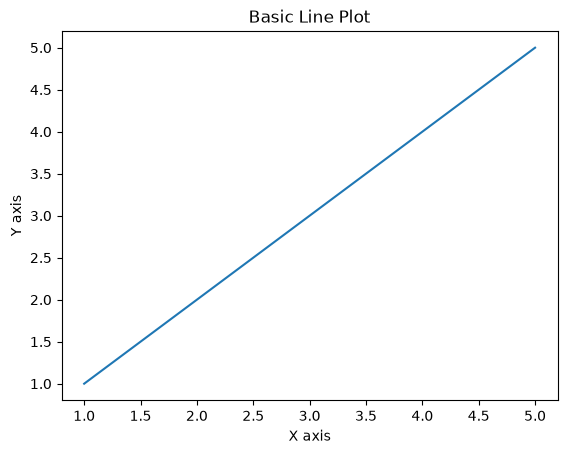

In [36]:
x= [1,2,3,4,5]
y =[1,2,3,4,5]

## create a line plot
plt.plot(x,y)
plt.xlabel('X axis')
plt.ylabel('Y axis')
plt.title("Basic Line Plot")
plt.show()

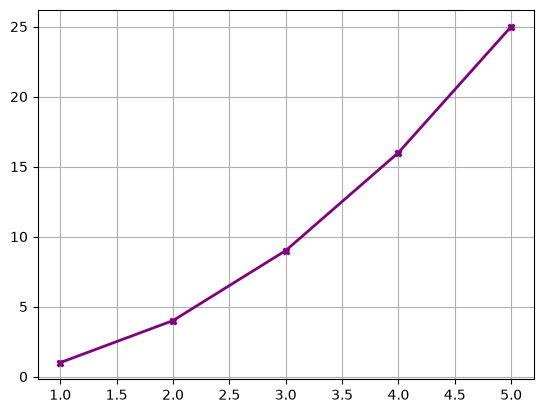

In [38]:
x=[1,2,3,4,5]
y=[1,4,9,16,25]

plt.plot(x,y,color='purple',linestyle='-',marker='X',linewidth=2,markersize=5)
plt.grid(True)

Text(0.5, 1.0, 'Plot4')

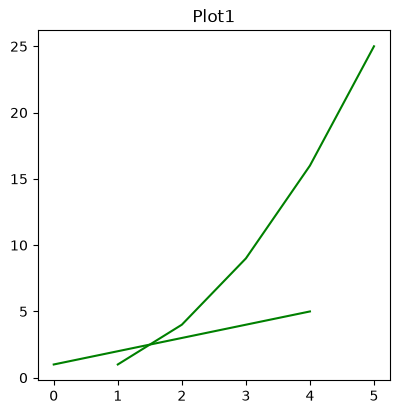

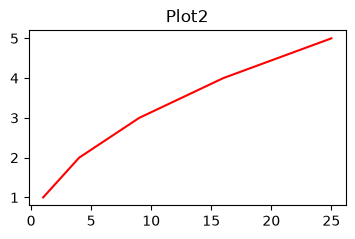

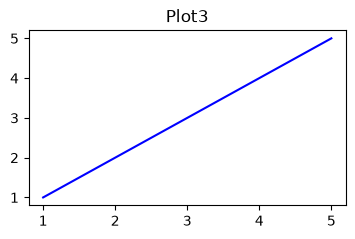

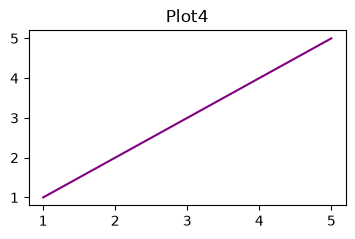

In [39]:
## Multiple Plots
##Sample data

x=[1,2,3,4,5]
y1=[1,4,9,16,25]
y2=[1,2,3,4,5]

plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.plot(x,y1,y2,color='green')
plt.title("Plot1")

plt.figure(figsize=(9,5))
plt.subplot(2,2,2)
plt.plot(y1,x,color='red')
plt.title("Plot2")

plt.figure(figsize=(9,5))
plt.subplot(2,2,4)
plt.plot(x,y2,color='blue')
plt.title("Plot3")

plt.figure(figsize=(9,5))
plt.subplot(2,2,4)
plt.plot(x,y2,color='purple')
plt.title("Plot4")





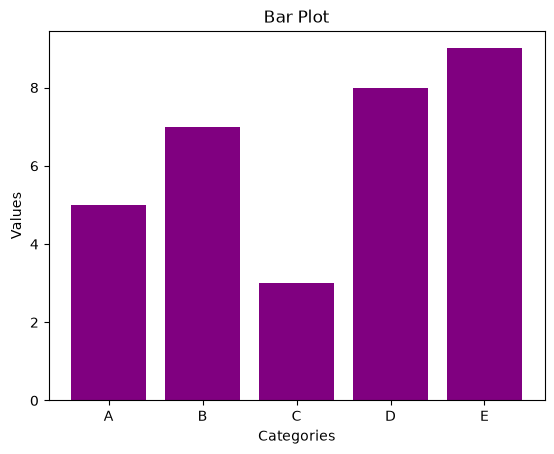

In [48]:
##Bar Plot

categories=['A','B','C','D','E']
values =[5,7,3,8,9]

##Create a bar plot

plt.bar(categories,values,color='purple')
plt.xlabel('Categories')
plt.ylabel('Values')
plt.title('Bar Plot')
plt.show()

**Histograms**

(array([1., 2., 3., 4., 5.]),
 array([1. , 1.8, 2.6, 3.4, 4.2, 5. ]),
 <BarContainer object of 5 artists>)

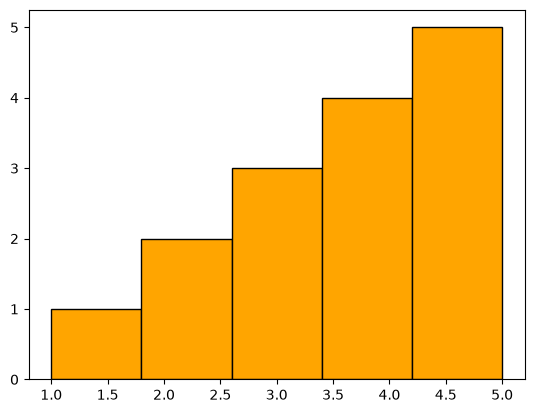

In [40]:
#Simple data
data =[1,2,2,3,3,3,4,4,4,4,5,5,5,5,5]
##Create a histogram
plt.hist(data,bins=5,color='orange',edgecolor='black')

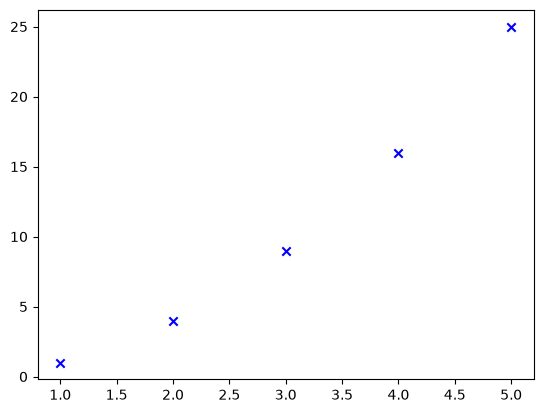

In [41]:
##Create a scatter plot
#Sample data

x=[1,2,3,4,5]
y=[1,4,9,16,25]
plt.scatter(x,y,color='blue',marker='x')

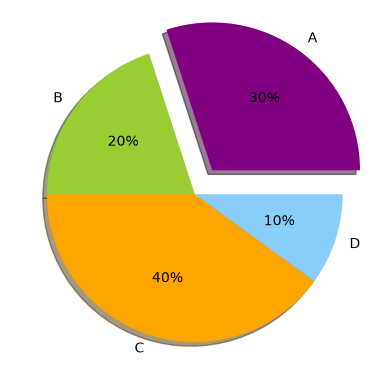

In [46]:
##Pie Chart

labels=['A','B','C','D']
sizes =[30,20,40,10]
colors =['purple','yellowgreen','orange','lightskyblue']
explode=(0.2,0,0,0) ##Move out the first slice

##create a pie chart
plt.pie(sizes,explode=explode,labels=labels,colors=colors,autopct="%0.0f%%",shadow=True)

In [47]:
import pandas as pd

sales_data_df=pd.read_csv('sales_data.csv')
sales_data_df.head(5)

,Transaction ID,Date,Product Category,Product Name,Units Sold,Unit Price,Total Revenue,Region,Payment Method
0,10001,2024-01-01,Electronics,iPhone 14 Pro,2,999.99,1999.98,North America,Credit Card
1,10002,2024-01-02,Home Appliances,Dyson V11 Vacuum,1,499.99,499.99,Europe,PayPal
2,10003,2024-01-03,Clothing,Levi's 501 Jeans,3,69.99,209.97,Asia,Debit Card
3,10004,2024-01-04,Books,The Da Vinci Code,4,15.99,63.96,North America,Credit Card
4,10005,2024-01-05,Beauty Products,Neutrogena Skincare Set,1,89.99,89.99,Europe,PayPal


In [73]:
sales_data_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    240 non-null    int64  
 1   Date              240 non-null    str    
 2   Product Category  240 non-null    str    
 3   Product Name      240 non-null    str    
 4   Units Sold        240 non-null    int64  
 5   Unit Price        240 non-null    float64
 6   Total Revenue     240 non-null    float64
 7   Region            240 non-null    str    
 8   Payment Method    240 non-null    str    
dtypes: float64(2), int64(2), str(5)
memory usage: 17.0 KB


In [48]:
##Plot total sales by products
total_sales_by_products=sales_data_df.groupby('Product Category')['Total Revenue'].sum()
print(total_sales_by_products)

Product Category
Beauty Products     2621.90
Books               1861.93
Clothing            8128.93
Electronics        34982.41
Home Appliances    18646.16
Sports             14326.52
Name: Total Revenue, dtype: float64


<Axes: xlabel='Product Category'>

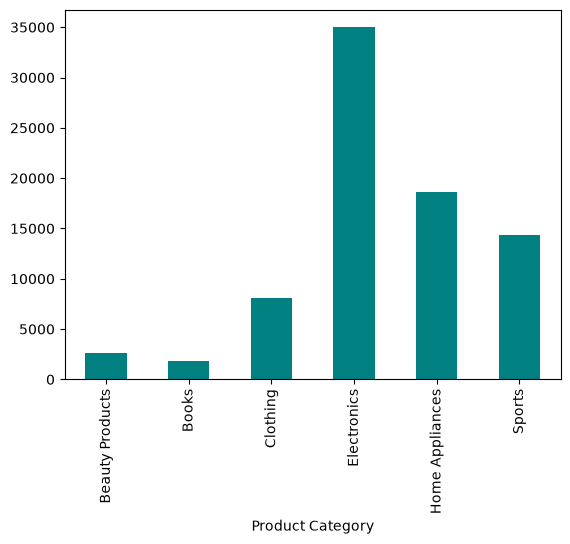

In [53]:
total_sales_by_products.plot(kind='bar',color='teal')

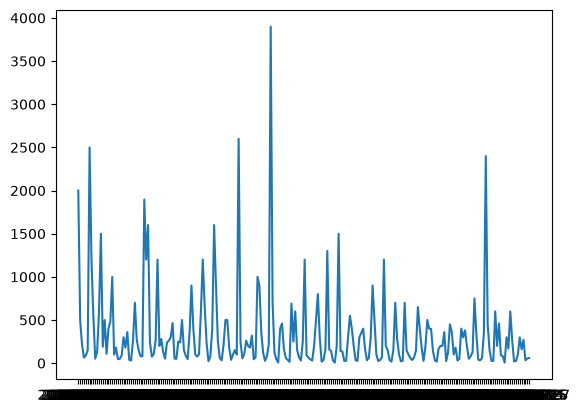

In [82]:
##plot sales trend over time
sales_trend = sales_data_df.groupby('Date')['Total Revenue'].sum().reset_index()
plt.plot(sales_trend['Date'],sales_trend['Total Revenue'])

**Data Visualization with SeaBorn**

In [83]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [54]:
import seaborn as meta

In [55]:
## Basics Plotting With seaborn
tips =meta.load_dataset('tips')
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


<function matplotlib.pyplot.show(close=None, block=None)>

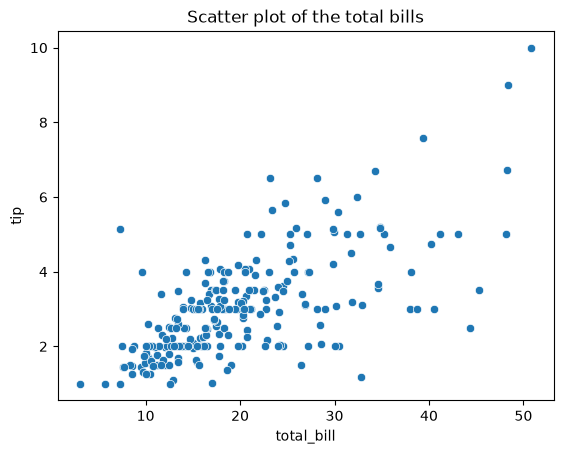

In [56]:
##Create a scatter
import matplotlib.pyplot as plt
meta.scatterplot(x='total_bill', y='tip', data=tips)

plt.title("Scatter plot of the total bills")

plt.show



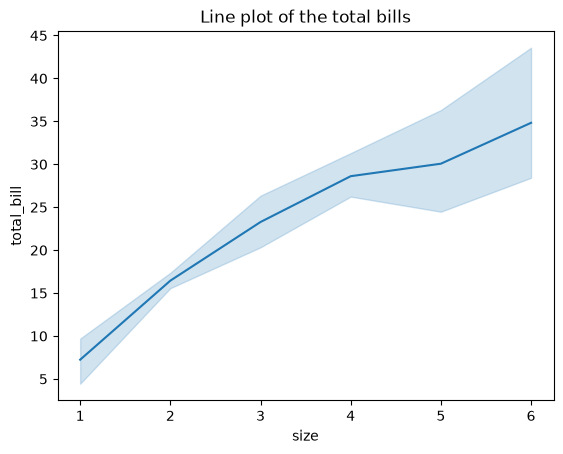

In [57]:
##Line Plot
meta.lineplot(x='size',y='total_bill',data=tips)
plt.title("Line plot of the total bills")
plt.show()

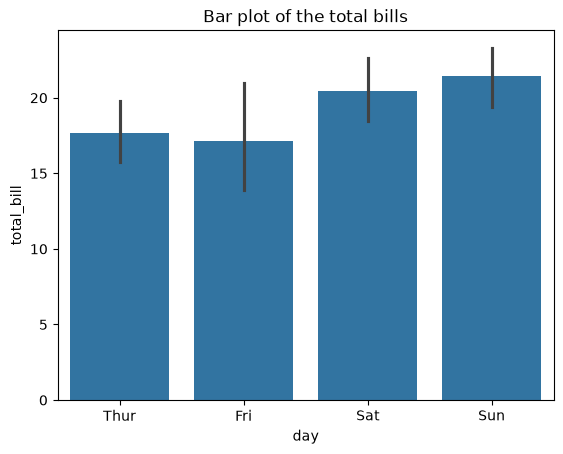

In [58]:
## Categories Plots 
## Bar plots

meta.barplot(x='day',y='total_bill',data=tips)
plt.title("Bar plot of the total bills")
plt.show()

<Axes: xlabel='day', ylabel='total_bill'>

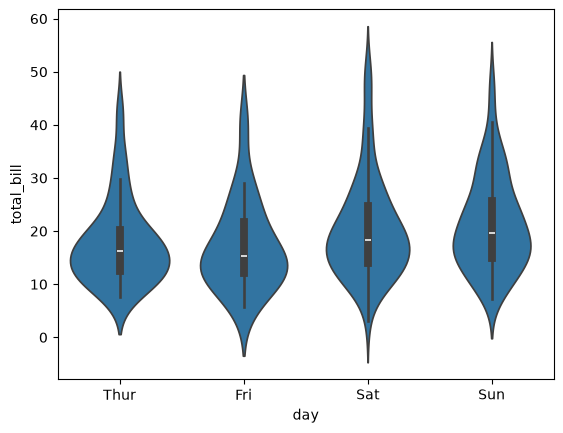

In [59]:
## Violin Plot

meta.violinplot(x='day',y='total_bill',data=tips)

<Axes: xlabel='total_bill', ylabel='Count'>

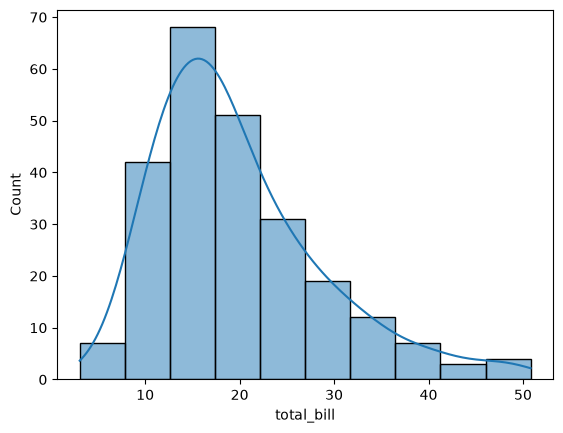

In [60]:
##Histogram

meta.histplot(tips['total_bill'],bins=10,kde=True)

<Axes: xlabel='total_bill', ylabel='Density'>

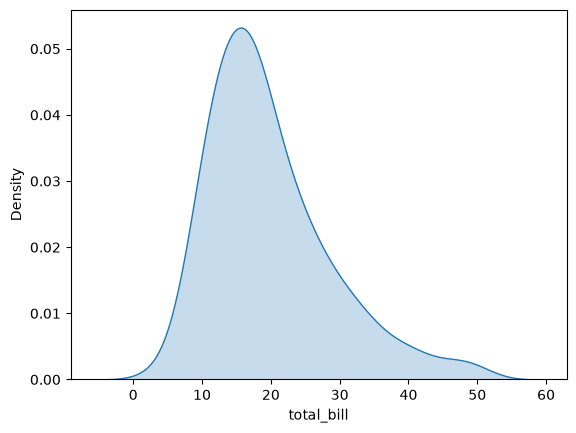

In [61]:
##KDE plot

meta.kdeplot(tips['total_bill'],fill=True)

In [62]:
import seaborn as meta

df =meta.load_dataset('titanic')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [63]:
df.isnull()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
887,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
888,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False
889,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [64]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [65]:
## Delete the rows or data point to handle missing values
df.shape

(891, 15)

In [66]:
df.dropna().shape ## not the correct ways of handling

(182, 15)

In [67]:
## Column wise deletion
df.dropna(axis=1)

,survived,pclass,sex,sibsp,parch,fare,class,who,adult_male,alive,alone
0,0,3,male,1,0,7.2500,Third,man,True,no,False
1,1,1,female,1,0,71.2833,First,woman,False,yes,False
2,1,3,female,0,0,7.9250,Third,woman,False,yes,True
3,1,1,female,1,0,53.1000,First,woman,False,yes,False
4,0,3,male,0,0,8.0500,Third,man,True,no,True
...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,0,0,13.0000,Second,man,True,no,True
887,1,1,female,0,0,30.0000,First,woman,False,yes,True
888,0,3,female,1,2,23.4500,Third,woman,False,no,False
889,1,1,male,0,0,30.0000,First,man,True,yes,True


**Imputation Missing Values**

# 1- Mean Value Imputation

<Axes: xlabel='age', ylabel='Count'>

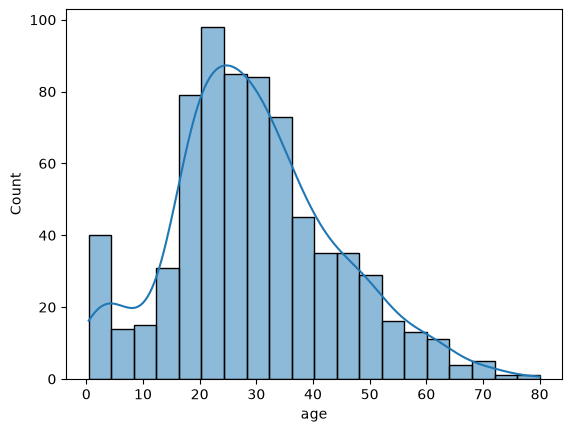

In [7]:
meta.histplot(df['age'],kde=True)

In [68]:
df['age_mean'] =df['age'].fillna(df['age'].mean()) ## We use in the palce of null value
df[['age_mean','age']]

,age_mean,age
0,22.000000,22.0
1,38.000000,38.0
2,26.000000,26.0
3,35.000000,35.0
4,35.000000,35.0
...,...,...
886,27.000000,27.0
887,19.000000,19.0
888,29.699118,NaN
889,26.000000,26.0


# 2. Median Values Imputation - If we have outliers in the dataset

In [69]:
df['age_median'] = df['age'].fillna(df['age'].median())
df[['age','age_mean','age_median']]

,age,age_mean,age_median
0,22.0,22.000000,22.0
1,38.0,38.000000,38.0
2,26.0,26.000000,26.0
3,35.0,35.000000,35.0
4,35.0,35.000000,35.0
...,...,...,...
886,27.0,27.000000,27.0
887,19.0,19.000000,19.0
888,NaN,29.699118,28.0
889,26.0,26.000000,26.0


# 3.Mode Imputation Technique -- Categorical Values

In [70]:
df[df['embarked'].isnull()]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_mean,age_median
61,1,1,female,38.0,0,0,80.0,NaN,First,woman,False,B,NaN,yes,True,38.0,38.0
829,1,1,female,62.0,0,0,80.0,NaN,First,woman,False,B,NaN,yes,True,62.0,62.0


In [71]:
df['embarked'].unique()

<StringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str

In [ ]:
pip install scikit